# 06 — Uji Out-of-Sample: Arah & Volatilitas IHSG

**Phase 6/7 — Out-of-sample signal test.** Ini satu-satunya phase yang boleh menghasilkan klaim "sinyal". Phase 3–5 hanya menunjukkan asosiasi in-sample, yang bisa saja kebetulan atau hasil memilih model setelah melihat data. Di sini setiap model dilatih ulang **tiap bulan hanya dengan data yang sudah tersedia saat itu** (walk-forward, expanding window sejak 2010), lalu diuji pada hari-hari 2020–2026 yang belum pernah dilihatnya. Pembandingnya adalah tebakan naif.

Semua pilihan (fitur, model, metrik, periode, loss untuk uji Diebold–Mariano) mengikuti **README "Spesifikasi Phase 6 (dikunci sebelum Phase 5)"** persis. Tidak ada yang diubah berdasarkan Phase 5.

Tiga rincian implementasi ditetapkan sebelum hasil OOS dilihat, dan dicatat di README:
1. Logit tanpa regularisasi (tanpa hyperparameter, jadi tanpa tuning).
2. GARCH-X berbentuk perkalian: (ω + αε² + βσ²)·exp(γ·ΔlogVIX).
3. HAR-X mingguan dengan lag RV 1, 4, dan 13 minggu.

> **Peringatan tradeability (pra-registrasi):** Phase 4 menunjukkan bahwa sebagian besar reaksi IHSG terhadap kabar semalam terjadi di **gap pembukaan**. Daya prediksi close-to-close di bawah ini **TIDAK berarti dapat dieksploitasi**: harga penutupan hari t sudah lewat sebelum kabar semalam datang, dan harga pembukaan t+1 sudah menyerap sebagian besar kabar itu.

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Markdown, display

from src import analysis as an
from src import leadlag as ll
from src import oos
from src import plots
from src import regime as rg
from src import volatility as vol
from src.config import load_config, output_dir, series_table, target_ticker
from src.data_loader import load_prices

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 220)

cfg = load_config()
ocfg = cfg["oos"]
series = series_table(cfg, groups=("target", "core", "tools"))
transforms = dict(zip(series["id"], series["transform"]))
labels = series.set_index("id")["label"]
target_id, fx_id, eido_id, vix_id = cfg["project"]["target_id"], cfg["usdidr_retest"]["id"], ocfg["eido_id"], ocfg["vix_id"]
train_start, oos_start = ocfg["train_start"], ocfg["oos_start"]

proc = output_dir(cfg, "data/processed")
close = ll.drop_flagged(pd.read_parquet(proc / "prices_clean.parquet"), pd.read_parquet(proc / "stale_quote_flags.parquet"))
ids = list(dict.fromkeys(ocfg["main_features"] + ocfg["sensitivity_features"]))
frame = oos.feature_frame(close, target_id, ids, transforms, fx_id=fx_id, eido_id=eido_id)
r = lambda ids_: [f"r_{i}" for i in ids_]   # noqa: E731
models = {"utama": r(ocfg["main_features"]) + ["d_premium", "r_target"],
          "sensitivitas_granger": r(ocfg["sensitivity_features"]) + ["r_target"]}
print("Model utama:", models["utama"])
print("Sensitivitas (Granger-signifikan Phase 4):", models["sensitivitas_granger"], "| Brent:", labels["BRENT"])
print(f"Data: {frame.index.min():%d %b %Y} s/d {frame.index.max():%d %b %Y}; OOS mulai {oos_start}")

Model utama: ['r_EEM', 'r_SPX', 'r_VIX', 'd_premium', 'r_target']
Sensitivitas (Granger-signifikan Phase 4): ['r_EEM', 'r_SPX', 'r_NIFTY', 'r_VIX', 'r_COPPER', 'r_BRENT', 'r_target'] | Brent: dipilih dengan pengetahuan periode uji
Data: 03 Jan 2007 s/d 21 Oct 2026; OOS mulai 2020-01-01


## 1. Cek kebocoran (1/3): timing fitur

Setiap fitur di baris t harus sudah diketahui **setelah IHSG tutup di hari t** (16:00 WIB) dan **sebelum** return yang diprediksi (close t → close t+1) terealisasi.

| Fitur | Sumber | Tutup (WIB) | Diketahui sebelum IHSG t+1 buka? |
|---|---|---|---|
| r_EEM(t), r_SPX(t) | NYSE, sesi AS tanggal t | ±04:00 (t+1) | ya |
| Δlog VIX(t) | CBOE, sesi AS t | ±04:15 (t+1) | ya |
| Δpremium EIDO(t) | EIDO (NYSE t) vs IHSG(t)/USDIDR(t) | ±04:00 (t+1) | ya |
| r_IHSG(t) (kontrol) | BEI t | 16:00 (t) | ya |
| Nifty, Tembaga, Brent (sensitivitas) | NSE / futures t | ≤ ±04:00 (t+1) | ya |

Cek mekanis di bawah memeriksa bahwa tanggal realisasi target selalu sesudah tanggal fitur. Selain itu, walk-forward hanya melatih dengan baris yang **targetnya sudah terealisasi sebelum awal bulan** prediksi; tes `test_walk_forward_never_trains_on_unrealised_targets` membuktikannya.

In [2]:
audit = {name: oos.timing_audit(frame.loc[train_start:], feats) for name, feats in models.items()}
pd.DataFrame(audit).T

,n_baris,target_setelah_fitur,selisih_hari_min
utama,3838,True,1
sensitivitas_granger,3744,True,1


## 2. Arah IHSG(t+1): walk-forward, baseline naif vs logistic regression

- **Baseline naif:** frekuensi hari naik di data latih, dipakai sebagai probabilitas.
- **Logistic regression:** model utama dan model sensitivitas.
- **Metrik:** hit rate, log loss, Brier, AUC. Model utama dan baseline dibandingkan di **hari yang sama** (hari ketika semua fitur model utama tersedia).
- **Uji Diebold–Mariano vs baseline:** loss = log loss, varians HAC, koreksi Harvey–Leybourne–Newbold. Selisih negatif berarti model lebih baik.

In [3]:
pred = oos.walk_forward(frame, models, train_start, oos_start)
main_rows = oos.common_rows(pred, ["utama"])
mt_main = oos.metrics_table(main_rows, ["baseline", "utama"]).loc["OOS penuh"]
sens_rows = oos.common_rows(pred, ["sensitivitas_granger"])
mt_sens = oos.metrics_table(sens_rows, ["baseline", "sensitivitas_granger"]).loc["OOS penuh"]
display(pd.concat({"hari model utama": mt_main, "hari model sensitivitas": mt_sens}).round(4))
dm = {"utama": oos.diebold_mariano(oos.log_loss_obs(main_rows["y"], main_rows["p_utama"]),
                                   oos.log_loss_obs(main_rows["y"], main_rows["p_baseline"])),
      "sensitivitas_granger": oos.diebold_mariano(oos.log_loss_obs(sens_rows["y"], sens_rows["p_sensitivitas_granger"]),
                                                  oos.log_loss_obs(sens_rows["y"], sens_rows["p_baseline"]))}
print("Konvergensi logit di semua refit:", {m: bool(pred[f'konvergen_{m}'].all()) for m in models})
pd.DataFrame(dm).T

n  hit_rate  log_loss   brier     auc  frekuensi_naik
                        model                                                                         
hari model utama        baseline              1588    0.5189    0.6939  0.2504  0.4938          0.5189
                        utama                 1588    0.5869    0.6903  0.2432  0.6111          0.5189
hari model sensitivitas baseline              1520    0.5158    0.6945  0.2507  0.4931          0.5158
                        sensitivitas_granger  1520    0.5816    0.6888  0.2438  0.6085          0.5158

Konvergensi logit di semua refit: {'utama': True, 'sensitivitas_granger': True}


,n,selisih_loss_rata,dm_hln,p,p_satu_sisi_model_lebih_baik
utama,1588.0,-0.003647,-0.294991,0.768039,0.384020
sensitivitas_granger,1520.0,-0.005639,-0.516305,0.605716,0.302858


### Uji tambahan (*tidak dipra-registrasi*, hanya penjelas)

Kesimpulan yang **mengikat** adalah uji Diebold–Mariano dengan log loss di atas. Hit rate dan AUC bisa terlihat jauh lebih baik walaupun log loss hampir sama dengan naif. Penyebabnya: log loss menghukum keras prediksi yang **terlalu yakin tetapi salah**. Uji tambahan di bawah hanya menjelaskan perbedaan itu dan tidak mengubah kesimpulan:
- DM dengan loss Brier.
- Uji tanda (McNemar eksak) untuk hit rate.
- Log loss per sub-periode (bagian 4).

In [4]:
extra = {"DM Brier (utama vs baseline)": oos.diebold_mariano((main_rows["p_utama"] - main_rows["y"]) ** 2,
                                                       (main_rows["p_baseline"] - main_rows["y"]) ** 2),
         "uji tanda hit rate (utama vs baseline)": oos.hit_rate_test(main_rows["y"], main_rows["p_utama"], main_rows["p_baseline"])}
display(pd.DataFrame(extra).T)
loss_obs = oos.log_loss_obs(main_rows["y"], main_rows["p_utama"]) - oos.log_loss_obs(main_rows["y"], main_rows["p_baseline"])
conf = (main_rows["p_utama"] - 0.5).abs()
print("Kontribusi ke selisih log loss menurut keyakinan prediksi (|p - 0,5|, kuintil):")
pd.DataFrame({"selisih_log_loss": loss_obs, "kuintil_keyakinan": pd.qcut(conf.rank(method="first"), 5, labels=False)}) \
  .groupby("kuintil_keyakinan")["selisih_log_loss"].agg(["mean", "sum", "size"]).round(4)

,n,selisih_loss_rata,dm_hln,p,p_satu_sisi_model_lebih_baik,hanya_model_benar,hanya_baseline_benar
DM Brier (utama vs baseline),1588.0,-0.007206,-2.168756,0.030249,0.015125,NaN,NaN
uji tanda hit rate (utama vs baseline),NaN,NaN,NaN,0.000002,NaN,307.0,199.0


Kontribusi ke selisih log loss menurut keyakinan prediksi (|p - 0,5|, kuintil):


,mean,sum,size
kuintil_keyakinan,,,
0,-0.0083,-2.6328,318
1,-0.0110,-3.4742,317
2,-0.0010,-0.3176,318
3,-0.0494,-15.6520,317
4,0.0512,16.2859,318


,p_rata,frekuensi_naik,n
bin,,,
0,0.310,0.289,159
1,0.431,0.447,159
2,0.477,0.421,159
3,0.509,0.506,158
4,0.536,0.522,159
5,0.562,0.528,159
6,0.588,0.595,158
7,0.619,0.597,159
8,0.665,0.654,159


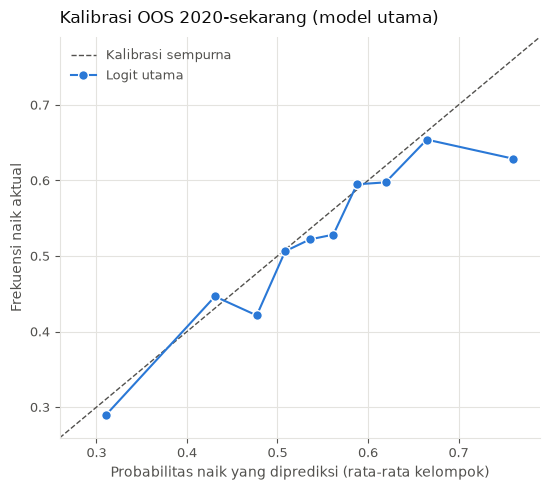

In [5]:
cal = {"Logit utama": oos.calibration_table(main_rows["y"], main_rows["p_utama"], ocfg["calibration_bins"])}
display(cal["Logit utama"].round(3))
fig = plots.plot_calibration(cal, "Kalibrasi OOS 2020-sekarang (model utama)")

### Sensitivitas EIDO z-score versi tren

**Label: "spesifikasi dipilih setelah melihat hasil Phase 4".** Model utama ditambah z-score spread log EIDO vs log IHSG_USD dengan tren deterministik. Parameter spread (konstanta, tren, beta, rata-rata, simpangan baku) diestimasi ulang di **data latih** setiap refit.

In [6]:
m_tren = {"eido_tren": models["utama"] + ["z_spread_tren"]}
pred_tren = oos.walk_forward(frame, m_tren, train_start, oos_start, trend_feature="z_spread_tren")
tr_rows = oos.common_rows(pred_tren, ["eido_tren"]).join(main_rows[["p_utama"]], how="inner")
mt_tren = oos.metrics_table(tr_rows, ["baseline", "utama", "eido_tren"]).loc["OOS penuh"]
dm_tren = {"eido_tren vs baseline": oos.diebold_mariano(oos.log_loss_obs(tr_rows["y"], tr_rows["p_eido_tren"]),
                                                        oos.log_loss_obs(tr_rows["y"], tr_rows["p_baseline"])),
           "eido_tren vs utama": oos.diebold_mariano(oos.log_loss_obs(tr_rows["y"], tr_rows["p_eido_tren"]),
                                                     oos.log_loss_obs(tr_rows["y"], tr_rows["p_utama"]))}
print("Label:", ocfg["label_eido_trend"])
display(mt_tren.round(4))
pd.DataFrame(dm_tren).T

Label: spesifikasi dipilih setelah melihat hasil Phase 4


,n,hit_rate,log_loss,brier,auc,frekuensi_naik
model,,,,,,
baseline,1588,0.5189,0.6939,0.2504,0.4938,0.5189
utama,1588,0.5869,0.6903,0.2432,0.6111,0.5189
eido_tren,1588,0.5806,0.6895,0.2431,0.6087,0.5189


,n,selisih_loss_rata,dm_hln,p,p_satu_sisi_model_lebih_baik
eido_tren vs baseline,1588.0,-0.004365,-0.360140,0.718791,0.359395
eido_tren vs utama,1588.0,-0.000718,-0.450787,0.652205,0.326102


## 3. Cek kebocoran (2/3 dan 3/3): uji placebo

- **Target diacak:** model dilatih dengan target y yang urutannya diacak (frekuensi naik tetap), lalu dievaluasi pada y asli. Tanpa kebocoran, rata-rata hasilnya setara baseline. Koefisien hasil pengacakan bertanda acak, jadi AUC per pengacakan bisa di atas atau di bawah 0,5; yang diperiksa adalah rata-ratanya.
- **Fitur sengaja bocor:** fitur diganti nilainya di hari t+1, hari yang sama dengan return yang diprediksi. Performa **harus melonjak**. Ini bukti bahwa pipeline bisa mendeteksi kebocoran. Ada tiga versi:
  1. **Semua fitur t+1**, termasuk IHSG(t+1) yang identik dengan target. Ini bocor kasar.
  2. **STI/KLCI/HSI t+1.** Pasar yang tutup bersamaan dengan IHSG t+1 ditambahkan ke model. Ini bocor halus yang realistis, misalnya kalau salah menyelaraskan tanggal pasar Asia.
  3. **Fitur AS t+1.** Ini *bukan* bocor yang informatif: sesi AS tanggal t+1 berjalan **setelah** IHSG t+1 tutup, jadi isinya lebih banyak tentang t+2. Versi ini diharapkan **tidak** melonjak, dan itu konsisten dengan struktur waktu di Phase 4.

"Melonjak" berarti hit rate atau AUC naik lebih dari 3 poin di atas model jujur.

In [7]:
plac = oos.shuffled_target_placebo(frame, models["utama"], train_start, oos_start, ocfg["placebo_seeds"])
plac_sum = oos.placebo_summary(plac)
display(plac.round(4))
display(pd.Series(plac_sum).to_frame("placebo target acak"))
external = [c for c in models["utama"] if c != "r_target"]
leak_rows = {}
for name, cols in {"bocor: semua fitur t+1": models["utama"], "bocor: fitur AS t+1": external}.items():
    p_leak = oos.walk_forward(oos.leaked_features(frame, cols), {"bocor": models["utama"]}, train_start, oos_start)
    leak_rows[name] = oos.metrics(*oos.common_rows(p_leak, ["bocor"])[["y", "p_bocor"]].to_numpy().T)
# Bocor halus yang realistis: seri SINKRON (tutup bersamaan dengan IHSG) di hari t+1 ditambahkan ke model utama
sync_ids = [s["id"] for s in cfg["core"] if s["session"] == "sync"]
frame_sync = oos.feature_frame(close, target_id, ids + sync_ids, transforms, fx_id=fx_id, eido_id=eido_id)
p_leak = oos.walk_forward(oos.leaked_features(frame_sync, r(sync_ids)), {"bocor": models["utama"] + r(sync_ids)},
                          train_start, oos_start)
leak_rows[f"bocor halus: {'/'.join(sync_ids)} t+1"] = oos.metrics(*oos.common_rows(p_leak, ["bocor"])[["y", "p_bocor"]].to_numpy().T)
leak = oos.leak_verdict(pd.DataFrame(leak_rows).T, mt_main.loc["utama", "hit_rate"], mt_main.loc["utama", "auc"])
leak.round(4)

,n,hit_rate,log_loss,brier,auc,frekuensi_naik,log_loss_baseline,selisih_log_loss,dm_hln,p_dm
seed,,,,,,,,,,
0,1588,0.5290,0.6901,0.2485,0.5527,0.5189,0.6939,-0.0038,-3.0355,0.0024
1,1588,0.5485,0.6899,0.2483,0.5534,0.5189,0.6939,-0.0040,-2.3183,0.0206
2,1588,0.5233,0.6893,0.2481,0.5878,0.5189,0.6939,-0.0046,-3.4388,0.0006
3,1588,0.5157,0.6984,0.2526,0.4479,0.5189,0.6939,0.0045,4.0473,0.0001
4,1588,0.5227,0.6956,0.2512,0.4729,0.5189,0.6939,0.0017,2.0982,0.0360
5,1587,0.5211,0.6944,0.2506,0.5220,0.5192,0.6938,0.0006,0.6103,0.5418
6,1588,0.5208,0.6932,0.2500,0.5157,0.5189,0.6939,-0.0007,-0.5225,0.6014
7,1588,0.5164,0.6976,0.2522,0.4740,0.5189,0.6939,0.0037,1.8607,0.0630
8,1588,0.5183,0.6944,0.2506,0.4967,0.5189,0.6939,0.0005,0.5500,0.5824


,placebo target acak
n_pengacakan,10.000000
rata_selisih_log_loss,-0.000260
porsi_signifikan_lebih_baik,0.300000
rata_auc,0.511617
rata_hit_rate,0.523521


,n,hit_rate,log_loss,brier,auc,frekuensi_naik,melonjak
bocor: semua fitur t+1,1587.0,0.9975,0.0055,0.0018,1.0000,0.5211,True
bocor: fitur AS t+1,1587.0,0.5728,0.6852,0.2453,0.5963,0.5211,False
bocor halus: STI/KLCI/HSI t+1,1462.0,0.6313,0.6498,0.2245,0.6873,0.5192,True


**Cara membaca placebo target acak.**
- **Tidak ada kebocoran.** Rata-rata selisih log loss di 10 pengacakan ≈ 0 dan AUC rata-rata ≈ 0,5.
- **DM per pengacakan bisa "signifikan" ke dua arah.** Fitur-fiturnya memang informatif, sehingga koefisien bertanda acak tetap membawa sedikit informasi urutan, ke arah yang benar atau yang salah. Karena prediksi placebo hampir konstan, selisih loss yang kecil pun terdeteksi.
- **Perbandingan dengan model asli:**
  - Perbaikan log loss model asli **berada di dalam rentang placebo**. Dari sisi log loss, model asli tidak bisa dibedakan dari kebetulan, konsisten dengan DM yang tidak signifikan.
  - Hit rate dan AUC model asli **melampaui semua** pengacakan.

## 4. Pelaporan per sub-periode (*ditambahkan setelah Phase 5, deskriptif*)

Bagian ini tidak ada di spesifikasi yang dikunci. Isinya: performa model utama di 2020–2022, di 2023–sekarang, dan di jendela episode Okt 2026 ([−20, +60] hari bursa, terpotong oleh akhir data). Jumlah hari di jendela Okt 2026 sangat sedikit.

In [8]:
td = close[target_id].dropna().index
w26 = rg.episode_window(td, list(cfg["regime"]["descriptive_only"].values())[0], tuple(cfg["regime"]["window_days"]))
subs = {f"{a[:4]}-{(b or 'sekarang')[:4] if b else 'sekarang'}": (a, b) for a, b in ocfg["subperiods"]}
subs[f"jendela Okt 2026 ({w26.start:%d %b} - {w26.end:%d %b %Y}, terpotong)"] = (w26.start, w26.end)
mt_sub = oos.metrics_table(main_rows, ["baseline", "utama"], subs)
print("Label:", ocfg["label_added_after_phase5"])
mt_sub.round(4)

Label: ditambahkan setelah Phase 5, deskriptif


n  hit_rate  log_loss   brier     auc  frekuensi_naik
periode                                            model                                                            
2020-2022                                          baseline  715    0.5231    0.6934  0.2501  0.4629          0.5231
                                                   utama     715    0.5958    0.7102  0.2464  0.6086          0.5231
2023-sekarang                                      baseline  873    0.5155    0.6943  0.2506  0.4918          0.5155
                                                   utama     873    0.5796    0.6740  0.2405  0.6135          0.5155
jendela Okt 2026 (18 Sep - 21 Oct 2026, terpotong) baseline   23    0.3478    0.7217  0.2643  0.2958          0.3478
                                                   utama      23    0.6087    0.6752  0.2409  0.7417          0.3478

## 5. Open-to-close (EKSPLORATIF)

Sesuai pra-registrasi: target diganti dengan **arah return open-to-close IHSG di t+1**, hanya di hari yang data Open-nya lolos cek (Open ≠ Close kemarin). Dengan begitu bagian "gap pembukaan" yang mustahil ditransaksikan ikut terbuang.

Ini yang lebih dekat dengan pertanyaan "bisakah dieksploitasi?". Tapi data Open 2020+ bermasalah di banyak hari (Phase 1), dan Open indeks memakai harga kemarin untuk saham yang belum diperdagangkan (Phase 4). **Hasil ini EKSPLORATIF.**

In [9]:
ohlc = load_prices([target_ticker(cfg)], start=cfg["project"]["start_date"], end=str(td.max().date()), verbose=False)[target_ticker(cfg)]
ohlc = ohlc.loc[ohlc.index.isin(td)]
split = ll.open_gap_split(ohlc)
frame_oc = frame.copy()
nxt = split["intraday"].reindex(frame_oc["target_date"]).to_numpy()
frame_oc["y_oc"] = np.where(np.isnan(nxt), np.nan, (nxt > 0).astype(float))
pred_oc = oos.walk_forward(frame_oc, {"utama_oc": models["utama"]}, train_start, oos_start, y_col="y_oc")
oc_rows = oos.common_rows(pred_oc, ["utama_oc"])
valid_share = frame_oc.loc[oos_start:, "y_oc"].notna().mean() / frame_oc.loc[oos_start:, "y"].notna().mean()
mt_oc = oos.metrics_table(oc_rows, ["baseline", "utama_oc"]).loc["OOS penuh"]
dm_oc = oos.diebold_mariano(oos.log_loss_obs(oc_rows["y"], oc_rows["p_utama_oc"]), oos.log_loss_obs(oc_rows["y"], oc_rows["p_baseline"]))
print(f"Hari OOS dengan Open valid: {valid_share:.1%}")
display(mt_oc.round(4))
pd.Series(dm_oc).to_frame("open-to-close vs baseline")

Hari OOS dengan Open valid: 81.1%


,n,hit_rate,log_loss,brier,auc,frekuensi_naik
model,,,,,,
baseline,1287,0.4670,0.6969,0.2519,0.5019,0.467
utama_oc,1287,0.5307,0.6941,0.2501,0.5611,0.467


,open-to-close vs baseline
n,1287.000000
selisih_loss_rata,-0.002843
dm_hln,-0.600986
p,0.547955
p_satu_sisi_model_lebih_baik,0.273978


## 6. Volatilitas: GARCH-X & HAR-X dengan VIX

**Validasi dulu:** GARCH buatan sendiri dengan γ = 0 harus cocok dengan `arch`, baik log-likelihood maupun parameternya. Validasi memakai data latih pertama (2010–2019). Return dalam persen.

Lalu dua perbandingan walk-forward dengan refit bulanan:
- **GARCH-X vs GARCH:** varians harian, dengan proxy realisasi = return kuadrat. Perubahan log VIX hari t (sesi AS) masuk ke varians IHSG hari t+1. Hari tanpa perdagangan VIX diberi perubahan 0.
- **HAR-X vs HAR:** RV mingguan = jumlah kuadrat return harian. Prediksi minggu depan dari lag RV 1, 4, dan 13 minggu (+ perubahan log VIX minggu ini).

Metrik QLIKE dan MSE, dengan uji Diebold–Mariano. Selisih negatif berarti versi dengan VIX lebih baik.

In [10]:
ret = (np.log(close[target_id].dropna()).diff() * 100).dropna()
vix_r = oos.own_returns(close[vix_id])
x_daily = vix_r.reindex(ret.index).fillna(0.0)
validation = vol.validate_against_arch(ret.loc[train_start:pd.Timestamp(oos_start) - pd.Timedelta(days=1)].to_numpy())
validation

,arch,sendiri,selisih_abs,selisih_relatif
mu,0.051714,0.051714,1.503753e-07,2.907811e-06
omega,0.026932,0.026931,3.077967e-07,1.142880e-05
alpha,0.101122,0.101122,6.111748e-07,6.043916e-06
beta,0.876020,0.876021,7.501271e-07,8.562900e-07
loglik (estimasi masing-masing),-3286.380056,-3286.380056,1.212356e-09,3.689033e-13
loglik sendiri di parameter arch,-3286.380056,-3286.380056,0.000000e+00,0.000000e+00


In [11]:
g_base = vol.garch_walk_forward(ret, x_daily, train_start, oos_start, use_x=False)
g_x = vol.garch_walk_forward(ret, x_daily, train_start, oos_start, use_x=True)
garch_cmp = vol.compare_losses(g_x, g_base, "r2")
print("gamma (koefisien VIX) per refit:", g_x.groupby("refit")["gamma"].first().describe()[["mean", "min", "max"]].round(3).to_dict())
garch_cmp

gamma (koefisien VIX) per refit: {'mean': 1.686, 'min': 1.411, 'max': 1.765}


,dengan_vix,tanpa_vix,n,selisih_loss_rata,dm_hln,p,p_satu_sisi_model_lebih_baik
loss,,,,,,,
QLIKE,1.003062,1.039078,1638,-0.036016,-2.407232,0.016184,0.008092
MSE,31.221557,31.946103,1638,-0.724546,-2.122343,0.033959,0.016979


In [12]:
rv = vol.weekly_rv(ret)
hf = vol.har_frame(rv, close[vix_id], ocfg["har_weeks"])
har_feats = [f"log_rv_{k}" for k in ocfg["har_weeks"]]
h_base = vol.har_walk_forward(hf, har_feats, train_start, oos_start)
h_x = vol.har_walk_forward(hf, har_feats + ["dlog_vix"], train_start, oos_start)
har_cmp = vol.compare_losses(h_x, h_base, "rv")
print(f"Minggu OOS: {len(h_x)}")
har_cmp

Minggu OOS: 353


,dengan_vix,tanpa_vix,n,selisih_loss_rata,dm_hln,p,p_satu_sisi_model_lebih_baik
loss,,,,,,,
QLIKE,2.592213,2.636288,353,-0.044075,-2.479692,0.013617,0.006808
MSE,186.871276,202.279403,353,-15.408127,-1.767644,0.077987,0.038993


## 7. Simpan hasil

Semua tabel disimpan ke `reports/phase6/`.

In [13]:
tables = {"arah_metrik_utama": mt_main, "arah_metrik_sensitivitas": mt_sens, "arah_dm": pd.DataFrame(dm).T,
          "arah_kalibrasi_utama": cal["Logit utama"], "arah_eido_tren_metrik": mt_tren, "arah_eido_tren_dm": pd.DataFrame(dm_tren).T,
          "placebo_target_acak": plac, "placebo_bocor": leak, "timing_audit": pd.DataFrame(audit).T,
          "arah_subperiode": mt_sub, "open_to_close_metrik": mt_oc, "validasi_garch_vs_arch": validation,
          "vol_garch_vs_garchx": garch_cmp, "vol_har_vs_harx": har_cmp,
          "prediksi_arah": pred.drop(columns=[c for c in pred if c.startswith("konvergen_")])}
summary = {"oos": [oos_start, str(pred.index.max().date())], "train_start": train_start, "model": models,
           "dm_open_to_close": dm_oc, "placebo_ringkas": plac_sum, "porsi_hari_open_valid": float(valid_share),
           "label_eido_tren": ocfg["label_eido_trend"], "label_subperiode": ocfg["label_added_after_phase5"]}
paths = an.save_tables(output_dir(cfg, "reports", "phase6"), tables, summary)
[p.name for p in paths]

['arah_metrik_utama.csv',
 'arah_metrik_sensitivitas.csv',
 'arah_dm.csv',
 'arah_kalibrasi_utama.csv',
 'arah_eido_tren_metrik.csv',
 'arah_eido_tren_dm.csv',
 'placebo_target_acak.csv',
 'placebo_bocor.csv',
 'timing_audit.csv',
 'arah_subperiode.csv',
 'open_to_close_metrik.csv',
 'validasi_garch_vs_arch.csv',
 'vol_garch_vs_garchx.csv',
 'vol_har_vs_harx.csv',
 'prediksi_arah.csv',
 'summary.json']

## Ringkasan insight

Dibangun otomatis dari hasil di atas.

In [14]:
oc_info = {"hit_rate": mt_oc.loc["utama_oc", "hit_rate"], "hit_rate_naif": mt_oc.loc["baseline", "hit_rate"], "p": dm_oc["p"]}
summary_md = oos.phase6_summary(mt_main, dm["utama"], plac_sum, leak, {"GARCH-X (harian)": garch_cmp, "HAR-X (mingguan)": har_cmp}, oc_info)
extra_md = (f"- **Penjelas (tidak dipra-registrasi):** DM Brier p = {extra['DM Brier (utama vs baseline)']['p']:.3f}; "
            f"uji tanda hit rate p = {extra['uji tanda hit rate (utama vs baseline)']['p']:.1e}. Model menangkap ARAH, "
            "tetapi terlalu yakin di hari-hari ekstrem (kuintil keyakinan tertinggi menambah log loss), "
            "sehingga tidak lolos uji yang dikunci.")
display(Markdown(summary_md + "\n" + extra_md))

### Ringkasan Phase 6 (OUT-OF-SAMPLE 2020-sekarang, spesifikasi dikunci sebelum Phase 5)

- **Arah IHSG besok dari data semalam (1,588 hari):** model utama menebak arah benar 58.7% vs tebakan naif 51.9%; log loss 0.6903 vs 0.6939, AUC 0.611 vs 0.494. Diebold-Mariano (log loss): p = 0.768 -> **tidak terbukti lebih baik dari naif**.
- **Cek kebocoran:** target diacak (10x) -> rata-rata selisih log loss vs naif -0.0003, AUC rata-rata 0.512 (setara naif). Fitur sengaja bocor -> bocor: semua fitur t+1: hit rate 99.7%, AUC 1.000 (melonjak); bocor: fitur AS t+1: hit rate 57.3%, AUC 0.596 (TIDAK melonjak); bocor halus: STI/KLCI/HSI t+1: hit rate 63.1%, AUC 0.687 (melonjak).
- **GARCH-X (harian):** QLIKE dengan VIX 1.0031 vs tanpa 1.0391 (DM p = 0.0162) -> VIX **membantu**.
- **HAR-X (mingguan):** QLIKE dengan VIX 2.5922 vs tanpa 2.6363 (DM p = 0.0136) -> VIX **membantu**.
- **Open-to-close (EKSPLORATIF):** hit rate 53.1% vs naif 46.7%, DM p = 0.548.
- **Tradeability:** daya prediksi close-to-close TIDAK berarti dapat dieksploitasi; sebagian besar reaksi terhadap kabar semalam terjadi di gap pembukaan (Phase 4), sebelum siapa pun bisa bertransaksi di close.
- **Penjelas (tidak dipra-registrasi):** DM Brier p = 0.030; uji tanda hit rate p = 1.8e-06. Model menangkap ARAH, tetapi terlalu yakin di hari-hari ekstrem (kuintil keyakinan tertinggi menambah log loss), sehingga tidak lolos uji yang dikunci.

## Lampiran Teknis: grafik tambahan

Sel di bawah hanya **menampilkan hasil yang sudah ada**: membaca `reports/` dan `data/processed` lewat `src/report.py`, tanpa analisis atau parameter baru. Dipakai oleh `scripts/build_notebook_report.py` (Lampiran Teknis PDF).

{'selisih_maks_vs_reports': 4.316227389722371e-05, 'n': 1638, 'qlike': {'dengan_vix': 1.0031, 'tanpa_vix': 1.0391}}


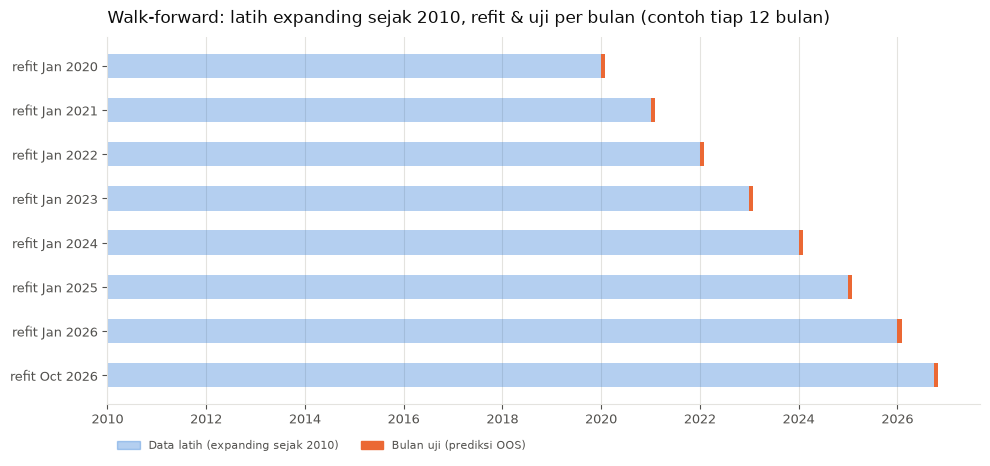

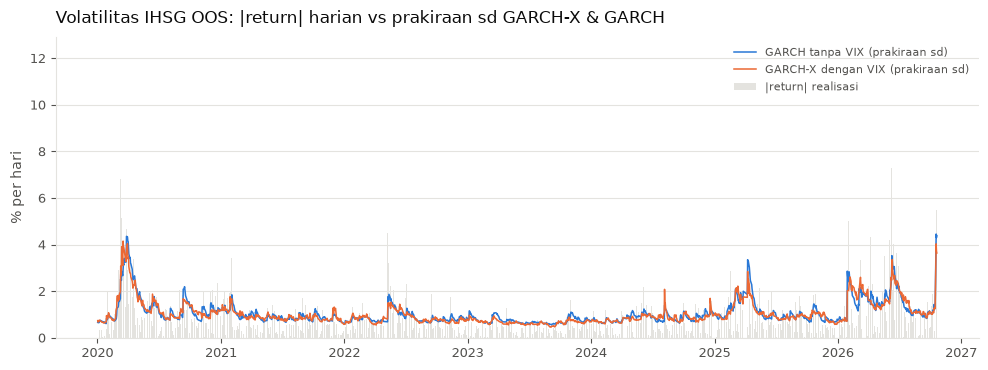

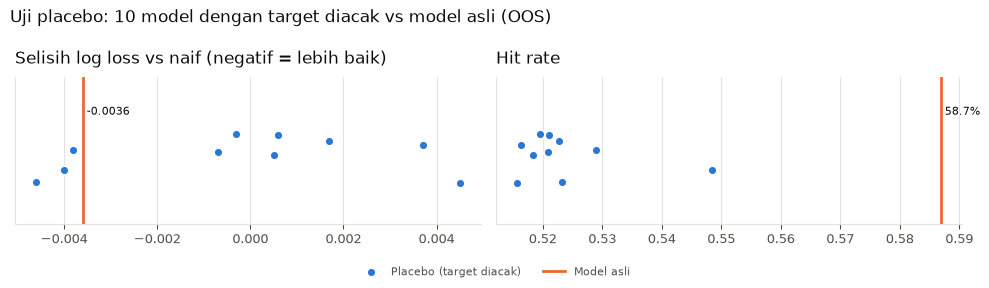

In [ ]:
from src import report
print(report.save_vol_predictions())   # hitung ulang; disimpan hanya kalau identik dengan reports/phase6
report.show("walkforward", "vol_forecast", "placebo")